## ⚙️ **Libraries Import**

In [215]:
# Set seed for reproducibility
SEED = 100

import numpy as np

# Import necessary libraries
import os
from datetime import datetime

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
from pathlib import Path


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
#from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
#!pip install torchview
#from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.6.0+cu124
Device: cuda


## 🔧 **Automatic Configuration**

In [216]:
#(LOCAL vs KAGGLE)

def get_paths():
    """It detects the enviroment and returns the correct path."""
    if os.path.exists('/kaggle/input'):
        print("🌍 Detetected enviroment: KAGGLE")
        !ls "/kaggle/input/dataset"
        input_dir = Path('/kaggle/input/datasetcomplete/dataset/')
        output_dir = Path('/kaggle/working/')
    else:
        print("💻 Detetected enviroment: LOCAL")
        # Impostate la vostra cartella di input e output locale
        input_dir = Path('../data/archive')
        output_dir = Path('../data/output')

        # Crea le cartelle se non esistono in locale
        output_dir.mkdir(parents=True, exist_ok=True)

    return input_dir, output_dir

INPUT_DIR, OUTPUT_DIR = get_paths()
print(f"Input directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


🌍 Detetected enviroment: KAGGLE
ls: cannot access '/kaggle/input/dataset': No such file or directory
Input directory: /kaggle/input/datasetcomplete/dataset
Output directory: /kaggle/working


In [217]:
#creo cartella per i models
models_dir=OUTPUT_DIR/'models'
models_dir.mkdir(parents=True, exist_ok=True)

#setup Log file
csv_file = OUTPUT_DIR/"all_models_log.csv"

## **Constants**

In [218]:
#tutte le costanti utili in un unico posto :)
BATCH_SIZE = 64

# ImageNet normalization statistics
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


## ⏳ **Data Loading**

In [219]:
# I numpy sono nel dataset ora (MESSI SUCCESSIVAMENTE) 
train_images = np.load(INPUT_DIR/'train_images.npy')
train_masks = np.load(INPUT_DIR/'masks_cleaned.npy')
test_images = np.load(INPUT_DIR/'test_images.npy')
test_masks = np.load(INPUT_DIR/'test_masks.npy')
train_labels = pd.read_csv(INPUT_DIR/'train_labels.csv')

train_images=train_images.astype('float32')
train_masks=train_masks.astype('float32')
test_images=test_images.astype('float32')
test_masks=test_masks.astype('float32')

print(type(train_images))

# Get class names
class_names = train_labels['label']
#print(class_names)

print("Data loaded sucessfully!")
print(f"Train images shape: {train_images.shape}")
print(f"Train masks shape: {train_masks.shape}")
print(f"Test images shape: {test_images.shape}")
print(f"Test masks shape: {test_masks.shape}")
print(f"Train labels shape: {train_labels.shape}")
print(np.max(train_images))
print(np.min(train_images))

<class 'numpy.ndarray'>
Data loaded sucessfully!
Train images shape: (629, 224, 224, 3)
Train masks shape: (629, 224, 224, 1)
Test images shape: (477, 224, 224, 3)
Test masks shape: (477, 224, 224, 1)
Train labels shape: (629, 2)
0.98039216
0.0


## 🔎 **Data Analysis**

In [220]:
#LABELS ANALYSIS AND DISTRIBUTION
print(train_labels.describe())

print("\n--- Unique Labels ---")
unique_labels = train_labels['label'].unique()
print(unique_labels)

print("\n--- Label Distribution ---")
label_counts = train_labels['label'].value_counts()
label_percentages = train_labels['label'].value_counts(normalize=True) * 100
label_stats = pd.DataFrame({
    'count': label_counts,
    'percentage': label_percentages
})
print(label_stats.round(2))

        sample_index      label
count            629        629
unique           629          4
top     img_0690.png  Luminal B
freq               1        219

--- Unique Labels ---
['Triple negative' 'Luminal B' 'Luminal A' 'HER2(+)']

--- Label Distribution ---
                 count  percentage
label                             
Luminal B          219       34.82
Luminal A          175       27.82
HER2(+)            159       25.28
Triple negative     76       12.08


In [221]:
#number of classes
NUM_CLASSES = len(unique_labels)

## 🔄 **Data Processing**

In [222]:
# Target preparation

# Define the mapping between textual labels and numerical value (enum)
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}

# Add new column 'target' to train_labels dataframe
train_labels['target'] = train_labels['label'].map(label_mapping)
target = np.array(train_labels['target']).astype('int64')

# weight = (num_total_training / (num_classes * num_for_class))
# Reindex label_stats to follow the explicit mapping order instead of alphabetical order
ordered_labels = [label for label, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
label_stats_ordered = label_stats.reindex(ordered_labels)
class_weights = (len(train_labels) / (NUM_CLASSES * label_stats_ordered['count'])).astype(np.float32)

# Create list useful later for tensor transformation
class_weights_list = list(class_weights)
print(f"Balanced WEIGHT for each class:\t{class_weights_list}")
print(f"Class order: {ordered_labels}")
class_weights_tensor = torch.tensor(class_weights_list, dtype=torch.float32).to(device)

Balanced WEIGHT for each class:	[0.8985714316368103, 0.7180365324020386, 0.9889937043190002, 2.0690789222717285]
Class order: ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']


In [223]:
#SPLIT IN TRAIN & VAL

X_train , X_val, M_train, M_val, y_train, y_val = train_test_split(train_images, train_masks, target, test_size=0.2, random_state=SEED,  stratify=target)

# Print the shapes of the resulting datasets
print("Training Data Shape:", X_train.shape)
print("Training Label Shape:", y_train.shape)
print("Validation Data Shape:", X_val.shape)
print("Validation Label Shape:", y_val.shape)
print("Mask training shape: ", M_train.shape)
print("Mask validations shape: ", M_val.shape)


Training Data Shape: (503, 224, 224, 3)
Training Label Shape: (503,)
Validation Data Shape: (126, 224, 224, 3)
Validation Label Shape: (126,)
Mask training shape:  (503, 224, 224, 1)
Mask validations shape:  (126, 224, 224, 1)


In [224]:
# Define the input shape based on the training data
INPUT_SHAPE = (X_train.shape[3], X_train.shape[1], X_train.shape[2])
print(INPUT_SHAPE)

(3, 224, 224)


In [225]:
class MyDataset(torch.utils.data.Dataset):
    """Custom PyTorch Dataset with optional augmentation and normalization."""

    def __init__(self, data, labels,mask, augmentation=None, normalize_imagenet=False):
        """
        Args:
            data: numpy array of images (N, C, H, W) in range [0, 1]
            labels: numpy array of labels
            augmentation: transforms for data augmentation
            normalize_imagenet: whether to apply ImageNet normalization
        """
        self.data = torch.from_numpy(data).permute(0, 3, 1, 2)
        self.mask = torch.from_numpy(mask).permute(0, 3, 1, 2)
        self.labels = torch.from_numpy(labels).squeeze().long()
        self.augmentation = augmentation
        self.normalize_imagenet = normalize_imagenet

        if normalize_imagenet:
            self.normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
        else:
            self.normalize = None
        

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx].clone() # Clone to avoid modifying original
        label = self.labels[idx]
        mask = self.mask[idx].clone()
        # Apply augmentation if provided (on images in [0, 1] range)
        if self.augmentation:
            #from torchvision import tv_tensors
            #image = tv_tensors.Image(image)
            #mask = tv_tensors.Mask(mask)
            image, mask = self.augmentation(image, mask)
        if self.normalize:
            image = self.normalize(image)

        return image, label, mask

In [226]:
from torchvision.transforms import v2
from torchvision.transforms import functional as F
from torchvision.transforms import InterpolationMode

class ClinicalAugmentation:
    def __init__(self, fill_color_img):
        self.fill_color_img = fill_color_img
        
        # Trasformazioni SOLO per l'immagine (colore, blur, erasing)
        self.photometric = v2.Compose([
            v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
            v2.RandomApply([v2.GaussianBlur(kernel_size=(3, 5), sigma=(0.1, 2.0))], p=0.3),
            #v2.RandomErasing(p=0.2, scale=(0.02, 0.1), ratio=(0.3, 3.3), value=0),
        ])

    def __call__(self, image, mask):
        # --- 1. TRASFORMAZIONI GEOMETRICHE (Sincronizzate) ---
        
        # Random Horizontal Flip
        if random.random() > 0.5:
            image = F.hflip(image)
            mask = F.hflip(mask)
            
        # Random Vertical Flip
        if random.random() > 0.5:
            image = F.vflip(image)
            mask = F.vflip(mask)
            
        # Random Rotation & Affine
        # Genera parametri casuali
        angle = random.uniform(-45, 45)
        translate_x = random.uniform(-0.1 * image.shape[-1], 0.1 * image.shape[-1])
        translate_y = random.uniform(-0.1 * image.shape[-2], 0.1 * image.shape[-2])
        scale = random.uniform(0.9, 1.1)
        shear = random.uniform(-10, 10)

        # Applica all'IMMAGINE (Bilineare, fill grigio)
        image = F.affine(
            image, 
            angle=angle, 
            translate=(translate_x, translate_y), 
            scale=scale, 
            shear=shear,
            interpolation=InterpolationMode.BILINEAR,
            fill=self.fill_color_img
        )
        
        # Applica alla MASCHERA (Nearest, fill nero)
        mask = F.affine(
            mask, 
            angle=angle, 
            translate=(translate_x, translate_y), 
            scale=scale, 
            shear=shear,
            interpolation=InterpolationMode.NEAREST,
            fill=0
        )
        
        # --- 2. TRASFORMAZIONI FOTOMETRICHE (Solo Immagine) ---
        # Applicate dopo la geometria per evitare artefatti strani sui bordi neri/grigi
        image = self.photometric(image)
        
        return image, mask

In [227]:
fill_color = 180.0 / 255.0
train_transforms = ClinicalAugmentation(fill_color_img=fill_color)

train_ds = MyDataset(X_train, y_train,M_train, augmentation=train_transforms, normalize_imagenet=True)
val_ds   = MyDataset(X_val, y_val,M_val, augmentation=None, normalize_imagenet=True)

In [228]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [229]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)


In [230]:
# print batch shape
for xb, yb, zb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    print("Masks batch shape:", zb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([32, 3, 224, 224])
Labels batch shape: torch.Size([32])
Masks batch shape: torch.Size([32, 1, 224, 224])


Luminal A
Luminal A
HER2(+)
Luminal B
Triple negative
HER2(+)
Luminal A
HER2(+)


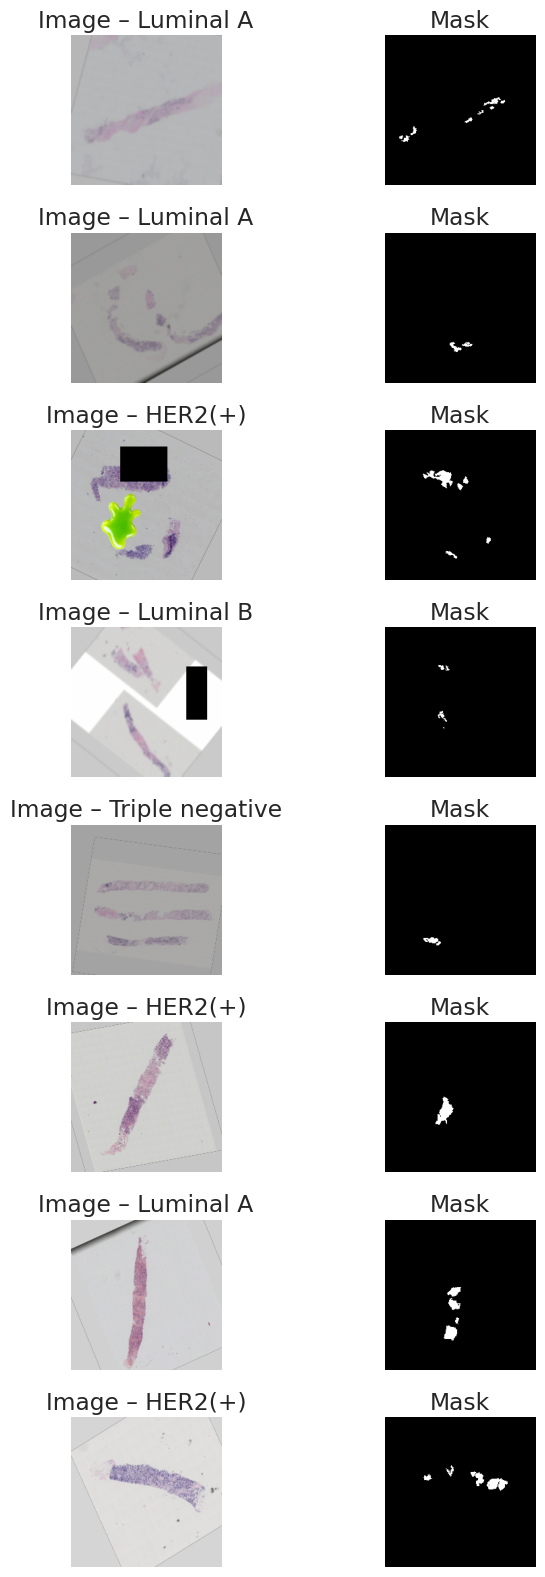

In [231]:
def denormalize(tensor):
    """Reverses ImageNet normalization for visualization."""
    tensor = tensor.clone()
    mean = torch.tensor(IMAGENET_MEAN, dtype=torch.float32, device=tensor.device).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD, dtype=torch.float32, device=tensor.device).view(3, 1, 1)
    tensor.mul_(std).add_(mean)
    return tensor

images, labels, mask = next(iter(train_loader))

num_examples = 8
plt.figure(figsize=(8, 2 * num_examples))

for i in range(num_examples):
    # ---- IMMAGINE ----
    ax = plt.subplot(num_examples, 2, 2*i + 1)
    
    img_tensor = denormalize(images[i])
    img = img_tensor.permute(1, 2, 0).cpu().numpy()
    img = np.clip(img, 0, 1)
    
    plt.imshow(img)
    
    label_idx = labels[i].item()
    
    label_name = ordered_labels[label_idx]
    print(label_name)
    plt.title(f"Image – {label_name}")
    plt.axis("off")
    
    # ---- MASK ----
    ax = plt.subplot(num_examples, 2, 2*i + 2)
    
    mask_i = mask[i, 0].cpu().numpy()  # (224,224)
    plt.imshow(mask_i, cmap="gray")
    plt.title("Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 🧮 **Network Parameters**

In [232]:
#MODEL PARAMETERS
EXPERIMENT_NAME = "transfer_learning_with_mask"
MODEL_NAME="MobileNet"
FINE_TUNING = False
IMAGE_AUG = False

# Training parameters
LEARNING_RATE = 1e-3
EPOCHS = 300
PATIENCE = 50


# Regularisation
DROPOUT_RATE = 0.4   # Dropout probability
L1_LAMBDA = 0.0          # L1 penalty NON È USATA PER ORA
L2_LAMBDA = 1e-5          # L2 penalty NON È USATA PER ORA

# Set up loss function
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

##  🧠 **Training Functions**

In [233]:
def train_one_epoch(model, train_loader,criterion, optimizer, scaler, device):
    """Train for one epoch."""
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    for inputs, targets, masks in train_loader:
        inputs, targets, masks = inputs.to(device), targets.to(device), masks.to(device)
        masks = masks.float().to(device)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs, masks)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def validate_one_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets, masks in val_loader:
            inputs, targets, masks = inputs.to(device), targets.to(device), masks.to(device)
            masks = masks.float().to(device)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs,masks)
                loss = criterion(logits, targets)

            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, verbose=1, experiment_name=""):
    """Train the neural network model."""

    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1={val_f1:.4f}")

        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load(OUTPUT_DIR/'models'/(experiment_name+'_model.pt')))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    if patience == 0:
        torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))

    return model, training_history

## 🛠️ **Transfer Learning**

In [234]:


class CnnMask(nn.Module):
    def __init__(self):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))   # output: (B, 64, 1, 1)
        )

        self.out_features = 64

    def forward(self, x):
        x = self.block(x)
        return x.view(x.size(0), -1)

In [235]:
class ModelTransferLearningDual(nn.Module):
    """
    CNN model with pretrained weights for transfer learning.

    IMPORTANT: This model expects ImageNet-normalized inputs!
    Images should be normalized with mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225]
    """

    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True):
        super().__init__()

        # 1 Load MobileNetV3Small backbone with ImageNet pretrained weights
        #self.backbone = torchvision.models.mobilenet_v3_small(
         #   weights=torchvision.models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
        #)
        #rgb_out_features = self.backbone.classifier[0].in_features
       # self.backbone.classifier = nn.Identity()
        self.backbone = torchvision.models.efficientnet_b3(weights='IMAGENET1K_V1')
        rgb_out_features = self.backbone.classifier[1].in_features # 1792
        self.backbone.classifier = nn.Identity()
        
        # 2. Freeze backbone if requested
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        
        # --------------------------------------------------------------
        # 2. Mask branch
        # --------------------------------------------------------------
        self.mask_branch = CnnMask()



        # --------------------------------------------------------------
        # 3. Final classifier: fusion of RGB + mask features
        # --------------------------------------------------------------
        fused_features = rgb_out_features + self.mask_branch.out_features
        hidden_dim = 512
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(fused_features, hidden_dim),      # 1280 → 256 (for EfficientNet)
            nn.BatchNorm1d(hidden_dim),               # Batch Normalization for stability
            nn.LeakyReLU(negative_slope=0.01),       # First non-linearity (LeakyReLU)
            nn.Dropout(p=dropout_rate),  # Additional regularization
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(negative_slope=0.01),       # First non-linearity (LeakyReLU)
            nn.Dropout(p=dropout_rate),
            nn.Linear(hidden_dim, num_classes)        # 256 → 4 (output classes)
        )
        

    def forward(self, x, mask):
        # img = (B, 3, H, W)
        # mask = (B, 1, H, W)

        # RGB branch
        f_img = self.backbone(x)
       # f_img = f_img.view(f_img.size(0), -1)   # flatten (B, 576)

        # Mask branch
        f_mask = self.mask_branch(mask)        # (B, 64)

        # fusion
        fused = torch.cat([f_img, f_mask], dim=1)

        # classification
        return self.classifier(fused)

In [236]:
# Create transfer learning model
tl_model = ModelTransferLearningDual(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)

# Display model summary
#summary(tl_model, input_size=INPUT_SHAPE)

In [237]:
# Setup training
optimizer = torch.optim.AdamW(tl_model.parameters(), lr = LEARNING_RATE, weight_decay= L2_LAMBDA)
#optimizer = torch.optim.Adam(tl_model.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [238]:
%%time

# Train with transfer learning
tl_model, tl_history = fit(
    model=tl_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    verbose=1,
    experiment_name=EXPERIMENT_NAME,
    patience=PATIENCE
)

final_val_f1 = round(max(tl_history['val_f1']) * 100, 2)
print(f'Final validation F1: {final_val_f1}%')

Training 300 epochs...
Epoch   1/300 | Train: Loss=1.4852, F1=0.2471 | Val: Loss=1.3765, F1=0.2499
Epoch   2/300 | Train: Loss=1.3962, F1=0.2762 | Val: Loss=1.3878, F1=0.2407
Epoch   3/300 | Train: Loss=1.3924, F1=0.2649 | Val: Loss=1.4142, F1=0.2444
Epoch   4/300 | Train: Loss=1.3599, F1=0.2915 | Val: Loss=1.4152, F1=0.1266
Epoch   5/300 | Train: Loss=1.3682, F1=0.3017 | Val: Loss=1.4122, F1=0.2263
Epoch   6/300 | Train: Loss=1.3738, F1=0.2880 | Val: Loss=1.4111, F1=0.2694
Epoch   7/300 | Train: Loss=1.3312, F1=0.3529 | Val: Loss=1.4539, F1=0.1823
Epoch   8/300 | Train: Loss=1.3643, F1=0.3219 | Val: Loss=1.4226, F1=0.2663
Epoch   9/300 | Train: Loss=1.3198, F1=0.3312 | Val: Loss=1.4268, F1=0.2045
Epoch  10/300 | Train: Loss=1.3439, F1=0.3291 | Val: Loss=1.4109, F1=0.2396
Epoch  11/300 | Train: Loss=1.3031, F1=0.3265 | Val: Loss=1.4301, F1=0.2388
Epoch  12/300 | Train: Loss=1.3012, F1=0.3638 | Val: Loss=1.4194, F1=0.2424
Epoch  13/300 | Train: Loss=1.3498, F1=0.3282 | Val: Loss=1.4060,

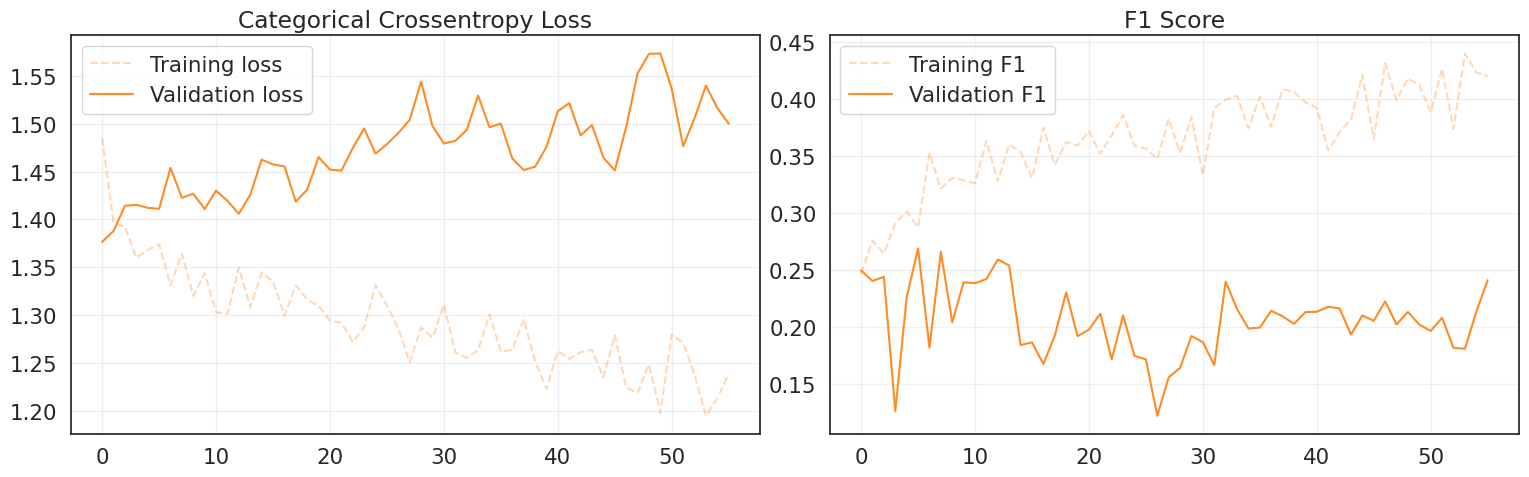

In [239]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(tl_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.2937
Precision over the validation set: 0.3680
Recall over the validation set: 0.2937
F1 score over the validation set: 0.2869
-----------------------------------
CLASS                ACCURACY
-----------------------------------
Luminal A            14.29%
Luminal B            47.73%
HER2(+)              15.62%
Triple negative      40.00%
-----------------------------------


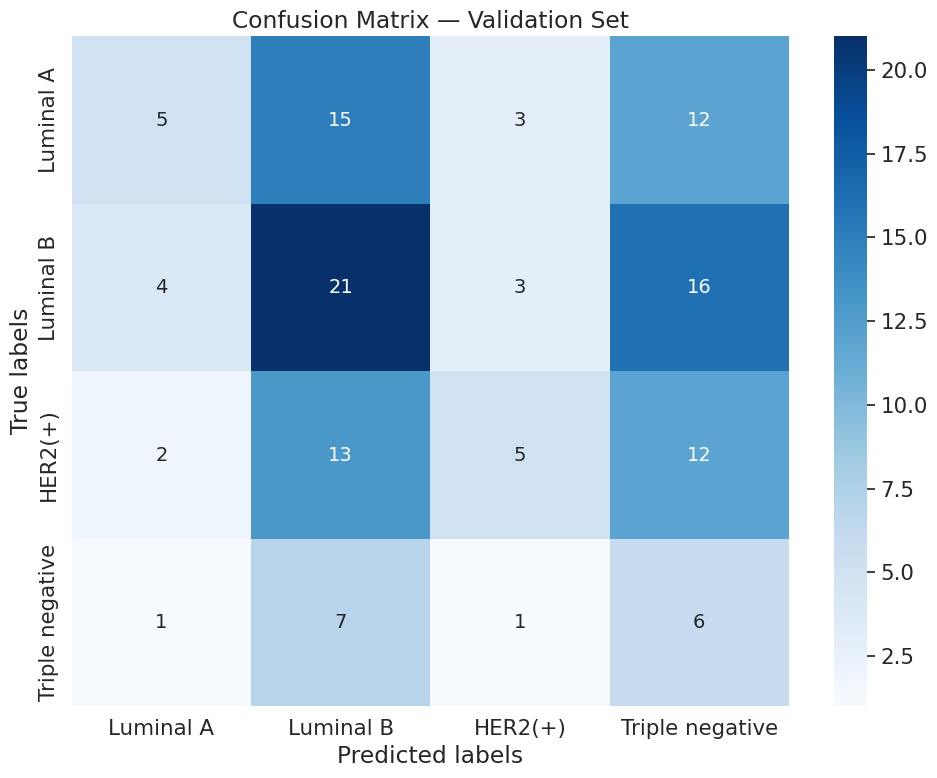

In [240]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
class_labels = ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']

val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb,zb in val_loader:
        xb = xb.to(device)
        zb = zb.to(device)
        # Forward pass: get model predictions
        logits = tl_model(xb,zb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Store accuracy per class with desired names
#Calcola il totale per ogni classe reale (somma delle righe)
true_totals = cm.sum(axis=1)
#Normalizza la matrice (gestendo la divisione per zero)
cm_perc = np.divide(cm.astype(float), true_totals[:, None], out=np.zeros_like(cm, dtype=float), where=true_totals[:, None]>0)
#Estrai la diagonale (che è l'accuratezza per ogni classe)
per_class_accuracy = cm_perc.diagonal()

accuracy_LA = per_class_accuracy[0]
accuracy_LB = per_class_accuracy[1]
accuracy_H2 = per_class_accuracy[2]
accuracy_TN = per_class_accuracy[3]

print("-" * 35)
print(f"{'CLASS':<20} {'ACCURACY'}")
print("-" * 35)

print(f"{'Luminal A':<20} {accuracy_LA:.2%}")
print(f"{'Luminal B':<20} {accuracy_LB:.2%}")
print(f"{'HER2(+)':<20} {accuracy_H2:.2%}")
print(f"{'Triple negative':<20} {accuracy_TN:.2%}")
print("-" * 35)

# Visualise confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels
            )
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

### 📋 **MODELS LOG**

In [241]:
#UPDATING LOG
hyperparams = {
    "batch_size": BATCH_SIZE,
    "dropout_rate": DROPOUT_RATE,
    "l1_lambda": L1_LAMBDA,
    "l2_lambda": L2_LAMBDA,
    "patience": PATIENCE
}

row = {
    "time": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "experiment_name": EXPERIMENT_NAME,
    "model_name": MODEL_NAME,
    "img_augmentation": IMAGE_AUG,
    "val_loss": tl_history['val_loss'],
    "val_f1": tl_history['val_f1'],
    **hyperparams,
    "accuracy_LA": accuracy_LA,
    "accuracy_LB": accuracy_LB,
    "accuracy_H2": accuracy_H2,
    "accuracy_TN": accuracy_TN,
}

new_row = pd.DataFrame([row])
if os.path.exists(csv_file):
    models_log = pd.read_csv(csv_file)
    models_log = models_log[models_log['experiment_name'] != row['experiment_name']]  # rimuovi duplicato
    models_log = pd.concat([models_log, new_row], ignore_index=True)
    models_log = models_log.sort_values(by='val_f1', ascending=False, ignore_index=True)
else:
    models_log = new_row

models_log.to_csv(csv_file, index=False)

In [242]:
# Load the transfer learning model
ft_model = ModelTransferLearningDual(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=False).to(device)
ft_model.load_state_dict(torch.load(OUTPUT_DIR/"models"/(EXPERIMENT_NAME+"_model.pt")))

# Unfreeze the last N layers of the backbone
N_LAYERS_TO_UNFREEZE = 15

# First, freeze everything
for param in ft_model.backbone.parameters():
    param.requires_grad = False

# Unfreeze last N layers (excluding classifier which is always trainable)
backbone_layers = list(ft_model.backbone.features.children())
for layer in backbone_layers[-N_LAYERS_TO_UNFREEZE:]:
    for param in layer.parameters():
        param.requires_grad = True

# Count trainable parameters
total_params = sum(p.numel() for p in ft_model.parameters())
trainable_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

# Display which layers are trainable
print("\nTrainable layers:")
for name, param in ft_model.named_parameters():
    if param.requires_grad:
        print(f"  {name}: {param.numel():,} parameters")

Total parameters: 11,804,972
Trainable parameters: 11,804,972
Frozen parameters: 0

Trainable layers:
  backbone.features.0.0.weight: 1,080 parameters
  backbone.features.0.1.weight: 40 parameters
  backbone.features.0.1.bias: 40 parameters
  backbone.features.1.0.block.0.0.weight: 360 parameters
  backbone.features.1.0.block.0.1.weight: 40 parameters
  backbone.features.1.0.block.0.1.bias: 40 parameters
  backbone.features.1.0.block.1.fc1.weight: 400 parameters
  backbone.features.1.0.block.1.fc1.bias: 10 parameters
  backbone.features.1.0.block.1.fc2.weight: 400 parameters
  backbone.features.1.0.block.1.fc2.bias: 40 parameters
  backbone.features.1.0.block.2.0.weight: 960 parameters
  backbone.features.1.0.block.2.1.weight: 24 parameters
  backbone.features.1.0.block.2.1.bias: 24 parameters
  backbone.features.1.1.block.0.0.weight: 216 parameters
  backbone.features.1.1.block.0.1.weight: 24 parameters
  backbone.features.1.1.block.0.1.bias: 24 parameters
  backbone.features.1.1.bloc

In [243]:
# Reuse datasets from transfer learning (with ImageNet normalization)
train_ft_ds = MyDataset(X_train, y_train,M_train, augmentation=train_transforms, normalize_imagenet=True)
val_ft_ds = MyDataset(X_val, y_val,M_val, augmentation=None, normalize_imagenet=True)

train_ft_loader = make_loader(train_ft_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_ft_loader = make_loader(val_ft_ds, BATCH_SIZE, shuffle=False, drop_last=False)

In [244]:
# Setup training with lower learning rate for fine-tuning
EXPERIMENT_NAME = "ft_"+EXPERIMENT_NAME
FT_LEARNING_RATE = 1e-4  # Lower learning rate for fine-tuning
#optimizer = torch.optim.Adam(ft_model.parameters(), lr=FT_LEARNING_RATE)
optimizer = torch.optim.AdamW(ft_model.parameters(), lr=FT_LEARNING_RATE, weight_decay = L2_LAMBDA)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [245]:
%%time
# Fine-tune the model
ft_model, ft_history = fit(
    model=ft_model,
    train_loader=train_ft_loader,
    val_loader=val_ft_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    verbose=5,
    experiment_name=EXPERIMENT_NAME,
    patience=PATIENCE
)

final_val_f1 = max(ft_history['val_f1'])
print(f'Final validation f1: {final_val_f1:.4f}')

Training 300 epochs...
Epoch   1/300 | Train: Loss=1.3490, F1=0.3256 | Val: Loss=1.4195, F1=0.2309
Epoch   5/300 | Train: Loss=1.2952, F1=0.3368 | Val: Loss=1.4349, F1=0.1775
Epoch  10/300 | Train: Loss=1.2313, F1=0.4203 | Val: Loss=1.4521, F1=0.2185
Epoch  15/300 | Train: Loss=1.1319, F1=0.4700 | Val: Loss=1.4500, F1=0.2494
Epoch  20/300 | Train: Loss=1.0559, F1=0.5028 | Val: Loss=nan, F1=0.2419
Epoch  25/300 | Train: Loss=0.9298, F1=0.5785 | Val: Loss=nan, F1=0.2401
Epoch  30/300 | Train: Loss=0.8398, F1=0.6036 | Val: Loss=1.6103, F1=0.2671
Epoch  35/300 | Train: Loss=0.7289, F1=0.6774 | Val: Loss=14.9974, F1=0.2936
Epoch  40/300 | Train: Loss=0.6279, F1=0.7309 | Val: Loss=nan, F1=0.2477
Epoch  45/300 | Train: Loss=0.5612, F1=0.7525 | Val: Loss=nan, F1=0.2418
Epoch  50/300 | Train: Loss=0.4573, F1=0.8218 | Val: Loss=nan, F1=0.2522
Epoch  55/300 | Train: Loss=0.4114, F1=0.8384 | Val: Loss=nan, F1=0.2256
Epoch  60/300 | Train: Loss=0.3385, F1=0.8756 | Val: Loss=2.1097, F1=0.2728
Epoch 

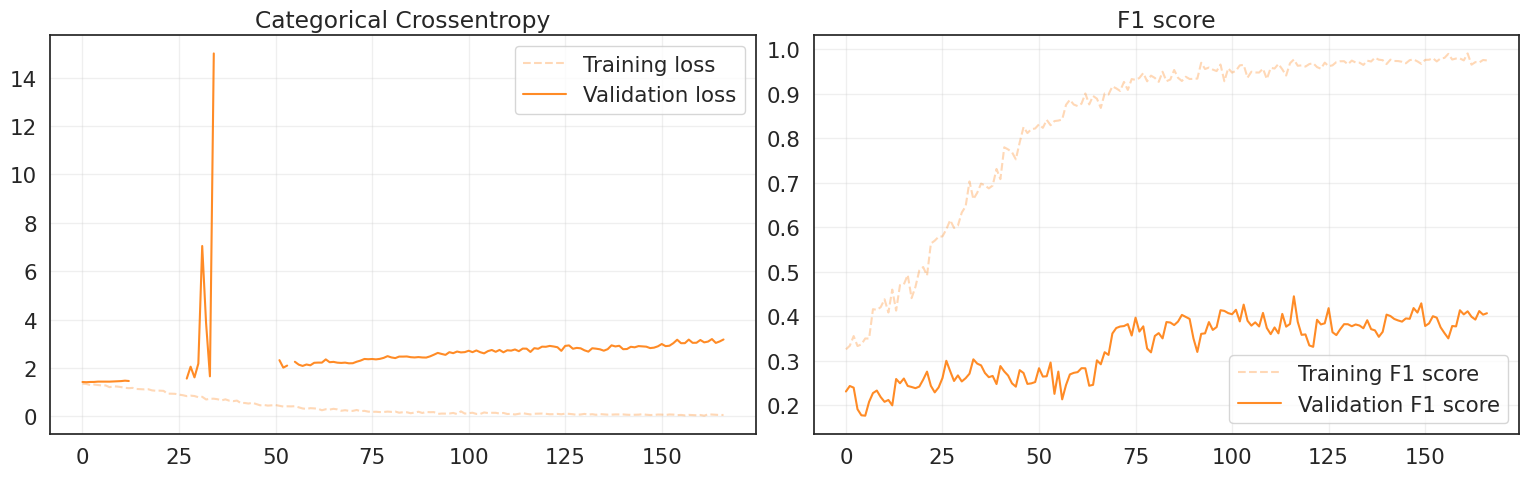

In [246]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(ft_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(ft_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(ft_history['train_f1'], label='Training F1 score', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(ft_history['val_f1'], label='Validation F1 score', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.4206
Precision over the validation set: 0.4214
Recall over the validation set: 0.4206
F1 score over the validation set: 0.4185
-----------------------------------
CLASS                ACCURACY
-----------------------------------
Luminal A            51.43%
Luminal B            40.91%
HER2(+)              34.38%
Triple negative      40.00%
-----------------------------------


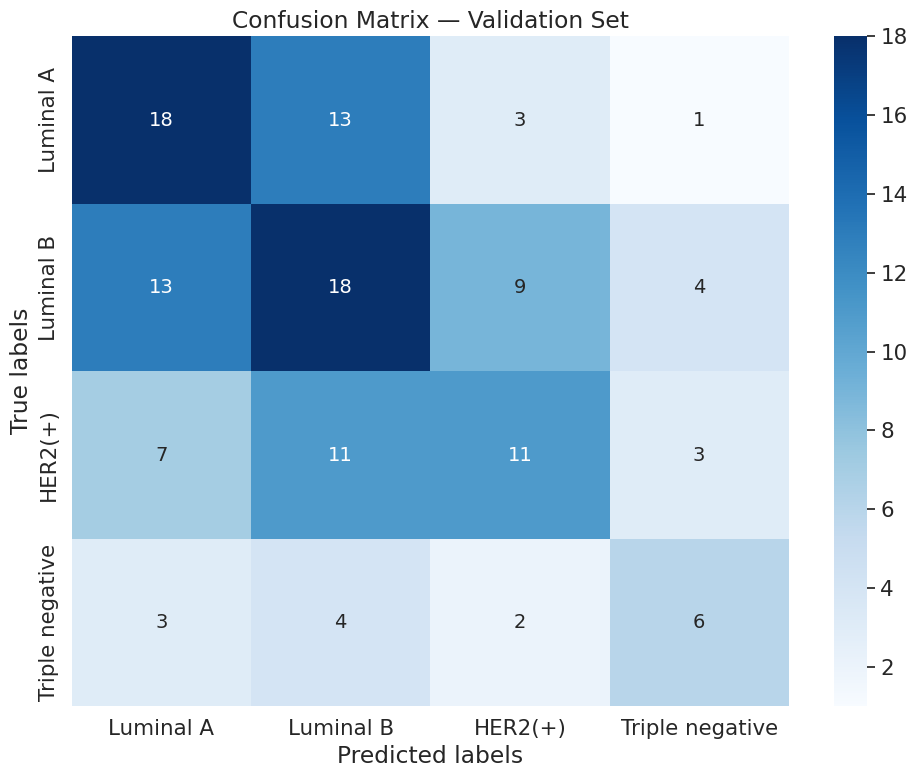

In [247]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
class_labels = ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']

val_ft_preds, val_ft_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb, zb in val_ft_loader:
        xb = xb.to(device)
        zb = zb.to(device)
        zb = zb.float().to(device)
        # Forward pass: get model predictions
        logits = ft_model(xb,zb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_ft_preds.append(preds)
        val_ft_targets.append(yb.numpy())

# Combine all batches into single arrays
val_ft_preds = np.concatenate(val_ft_preds)
val_ft_targets = np.concatenate(val_ft_targets)

# Calculate overall validation metrics
val_ft_acc = accuracy_score(val_ft_targets, val_ft_preds)
val_ft_prec = precision_score(val_ft_targets, val_ft_preds, average='weighted')
val_ft_rec = recall_score(val_ft_targets, val_ft_preds, average='weighted')
val_ft_f1 = f1_score(val_ft_targets, val_ft_preds, average='weighted')
print(f"Accuracy over the validation set: {val_ft_acc:.4f}")
print(f"Precision over the validation set: {val_ft_prec:.4f}")
print(f"Recall over the validation set: {val_ft_rec:.4f}")
print(f"F1 score over the validation set: {val_ft_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_ft_targets, val_ft_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Store accuracy per class with desired names
#Calcola il totale per ogni classe reale (somma delle righe)
true_totals = cm.sum(axis=1)
#Normalizza la matrice (gestendo la divisione per zero)
cm_perc = np.divide(cm.astype(float), true_totals[:, None], out=np.zeros_like(cm, dtype=float), where=true_totals[:, None]>0)
#Estrai la diagonale (che è l'accuratezza per ogni classe)
per_class_accuracy = cm_perc.diagonal()

accuracy_LA = per_class_accuracy[0]
accuracy_LB = per_class_accuracy[1]
accuracy_H2 = per_class_accuracy[2]
accuracy_TN = per_class_accuracy[3]

print("-" * 35)
print(f"{'CLASS':<20} {'ACCURACY'}")
print("-" * 35)

print(f"{'Luminal A':<20} {accuracy_LA:.2%}")
print(f"{'Luminal B':<20} {accuracy_LB:.2%}")
print(f"{'HER2(+)':<20} {accuracy_H2:.2%}")
print(f"{'Triple negative':<20} {accuracy_TN:.2%}")
print("-" * 35)

# Visualise confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels
            )
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

## 🕹️ **Test Inference**

In [248]:
#PREPARE DATA FOR TESTING
test_ds = MyDataset(test_images, np.zeros(len(test_images)),test_masks, augmentation=None, normalize_imagenet=True)
test_loader = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [249]:
# Load the  model for inference
best_model = ModelTransferLearningDual(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)
best_model.load_state_dict(torch.load(OUTPUT_DIR/"models"/(EXPERIMENT_NAME+"_model.pt")))
best_model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [250]:
# Collect predictions and ground truth labels
test_preds = []
with torch.no_grad():  # Disable gradient computation for inference
    for batch in test_loader:

        xb = batch[0].to(device)
        zb = batch[2].to(device)
        zb = zb.float().to(device)
        # Forward pass: get model predictions
        logits = best_model(xb, zb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        test_preds.append(preds)

# Combine all batches into single arrays
test_preds = np.concatenate(test_preds)

# Create CSV SUBMISSION
target_to_label = {
    0: 'Luminal A',
    1: 'Luminal B',
    2: 'HER2(+)',
    3: 'Triple negative'
}

# Ricostruisco il nome delle immagini: i=0 -> "img_0000.png", i=10 -> "img_0010.png"
filenames = [f"img_{i:04d}.png" for i in range(len(test_preds))]
predicted_labels = [target_to_label[p] for p in test_preds]

df_results = pd.DataFrame({
    "sample_index": filenames,
    "label": predicted_labels
})

csv_path = OUTPUT_DIR / 'test_predictions.csv'
df_results.to_csv(csv_path, index=False, header=True)
print(f"✅ test_predictions.csv created and saved successfully in: {csv_path}")

✅ test_predictions.csv created and saved successfully in: /kaggle/working/test_predictions.csv
